# ARTI 502 — Assignment 2 | CIFAR-10 CNN

**Training, testing, data augmentation and model comparison with PyTorch**  
2026 · Term 1 · Group: *fill in group number and member names in the report*

**Measured final benchmark:** EfficientNetV2-XL, **99.04%** test accuracy (9,904/10,000), **0.157579** mean test cross-entropy loss.

> **Reproducibility and attribution:** This notebook is a cleaned, ordered presentation of the original Colab experiments. Executed outputs for Tasks 1–4, ConvNeXtV2 curves, and EfficientNetV2-XL evaluation are retained from the original uploaded notebook. Some plots below are regenerated **only from real historical logs**; no model training or new testing was performed during this cleanup. The EfficientNetV2-XL model uses an **externally CIFAR-10-pretrained** checkpoint from [DeKUT-DSAIL](https://huggingface.co/DeKUT-DSAIL/efficientnetv2-xl-cifar10-upsample). Training from scratch or fine-tuning this model is **not claimed**.

**How to run:** Tasks 1–4 can run sequentially. Task 5's optional baseline training is disabled by default; historical plots run without training. The external XL benchmark requires an NVIDIA GPU and downloads/loads an ~831 MB checkpoint if it is not already in Google Drive. Do **not** needlessly rerun lengthy previous experiments.

## Environment and saved artifacts

The Colab runtime uses a GPU for advanced models. Checkpoints and report figures are saved to `MyDrive/ARTI502_Assignment2/`.

Run this setup once in a **fresh** Colab runtime. The `huggingface_hub` version is constrained to avoid the unrelated `datasets` dependency conflict encountered in the original notebook. Loading the model by architecture bypasses the Hub `config.json` issue.

In [ ]:
# Dependencies for Colab — run this once in a fresh runtime.
%pip -q install "timm>=1.0,<2" "huggingface_hub>=0.25,<2" safetensors

from pathlib import Path
import torch
from google.colab import drive

drive.mount('/content/drive')
DATA_PATH = Path('/content/cifar_data')
DATA_PATH.mkdir(parents=True, exist_ok=True)
SAVE_DIR = Path('/content/drive/MyDrive/ARTI502_Assignment2')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR = SAVE_DIR / 'Report_Figures'
REPORT_DIR.mkdir(exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| Artifacts:', SAVE_DIR)

## Task 1 — Download and inspect CIFAR-10

The dataset contains 50,000 training images and 10,000 official test images, with ten classes and a tensor shape of `(3, 32, 32)`. The successful execution output below is from the original Colab run.

In [3]:

# =========================================
# ARTI 502 - Assignment 2
# Task 1: Getting the CIFAR-10 Dataset
# =========================================

import torch
import torchvision
from torchvision import datasets, transforms
from pathlib import Path

# 1. Check PyTorch and GPU
print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Set dataset directory
DATA_PATH = Path("/content/cifar_data")
DATA_PATH.mkdir(parents=True, exist_ok=True)

# 3. Convert images to tensors
transform = transforms.ToTensor()

# 4. Load training dataset
train_dataset = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=True,
    download=True,
    transform=transform
)

# 5. Load testing dataset
test_dataset = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=False,
    download=True,
    transform=transform
)

# 6. Display dataset information
print("\nCIFAR-10 Dataset Loaded Successfully!")
print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))
print("Number of Classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)

# 7. Verify image dimensions
image, label = train_dataset[0]

print("\nSingle Image Shape:", image.shape)
print("Sample Label:", train_dataset.classes[label])


PyTorch Version: 2.11.0+cu130
Torchvision Version: 0.26.0+cu130
Device: cuda
GPU: NVIDIA L4


100%|██████████| 170M/170M [33:43<00:00, 84.3kB/s]



CIFAR-10 Dataset Loaded Successfully!
Training Images: 50000
Testing Images: 10000
Number of Classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Single Image Shape: torch.Size([3, 32, 32])
Sample Label: frog


## Task 2 — CNN architecture, training function and evaluation function

A custom CNN contains **three convolutional blocks**, each with `Conv2d`, `BatchNorm2d`, `ReLU` and `MaxPool2d`; a fully connected classifier produces ten class logits. The two reusable functions below show the forward pass, cross-entropy loss, backpropagation and metric calculation. The small synthetic-data test is **a unit test only**, not CIFAR-10 accuracy.

In [4]:

# ==========================================
# Task 2: Define a Convolutional Neural Network
# ==========================================

import torch
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        # First convolution block
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Second convolution block
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Third convolution block
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Fully connected classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.classifier(x)
        return x


# Create the model
model = CNN().to(device)

# Print its architecture
print(model)

# Test the forward pass with a dummy image
dummy_image = torch.randn(
    1, 3, 32, 32, device=device
)

model.eval()

with torch.no_grad():
    output = model(dummy_image)

print("\nDevice:", device)
print("Input Shape:", dummy_image.shape)
print("Output Shape:", output.shape)
print("CNN Model Created Successfully!")


CNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256,

In [5]:

# =====================================
# Task 2: Training Function
# =====================================

def train_one_epoch(model, train_loader, criterion, optimizer, device):

    # 1. Enable training mode
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    # 2. Process training batches
    for images, labels in train_loader:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # 3. Clear old gradients
        optimizer.zero_grad()

        # 4. Forward pass
        outputs = model(images)

        # 5. Calculate loss
        loss = criterion(outputs, labels)

        # 6. Backpropagation
        loss.backward()

        # 7. Update model weights
        optimizer.step()

        # 8. Calculate training statistics
        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += batch_size

    # 9. Calculate epoch averages
    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    return avg_loss, accuracy


print("Training function created successfully!")


Training function created successfully!


In [6]:

# =====================================
# Task 2: Testing / Evaluation Function
# =====================================

def evaluate(model, data_loader, criterion, device):

    # 1. Enable evaluation mode
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    # 2. Disable gradient calculations
    with torch.no_grad():

        for images, labels in data_loader:

            # Move data to GPU
            images = images.to(device)
            labels = labels.to(device)

            # 3. Forward pass
            outputs = model(images)

            # 4. Calculate loss
            loss = criterion(outputs, labels)

            # 5. Calculate statistics
            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += batch_size

    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    return avg_loss, accuracy


print("Evaluation function created successfully!")


Evaluation function created successfully!


In [7]:

from torch.utils.data import TensorDataset, DataLoader

# Create a separate temporary model
test_model = CNN().to(device)

# Synthetic images and labels for function testing
dummy_images = torch.randn(8, 3, 32, 32)
dummy_labels = torch.randint(0, 10, (8,))

dummy_loader = DataLoader(
    TensorDataset(dummy_images, dummy_labels),
    batch_size=4
)

criterion = nn.CrossEntropyLoss()

test_optimizer = torch.optim.Adam(
    test_model.parameters(),
    lr=0.001
)

# Check both functions
train_loss, train_acc = train_one_epoch(
    test_model, dummy_loader,
    criterion, test_optimizer, device
)

eval_loss, eval_acc = evaluate(
    test_model, dummy_loader,
    criterion, device
)

print("Training Function: PASSED")
print("Evaluation Function: PASSED")
print("Test Loss:", round(eval_loss, 4))
print("Test Accuracy:", round(eval_acc, 2), "%")


Training Function: PASSED
Evaluation Function: PASSED
Test Loss: 2.0924
Test Accuracy: 37.5 %


## Task 3 — Tensor dimensions and image visualization

`DataLoader` yields batches shaped `(N, C, H, W)`. For plotting, the tensor layout is converted from `(C, H, W)` to `(H, W, C)`.

In [8]:

# ======================================
# Task 3: Loading and Inspecting CIFAR-10
# ======================================

from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATA_PATH = Path("/content/cifar_data")

try:
    train_dataset = datasets.CIFAR10(
        root=str(DATA_PATH),
        train=True,
        download=False,
        transform=transforms.ToTensor()
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=128,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    images, labels = next(iter(train_loader))

    print("Dataset READY!")
    print("Images Tensor Shape:", images.shape)
    print("Labels Tensor Shape:", labels.shape)
    print("Images Data Type:", images.dtype)
    print("Pixel Min:", images.min().item())
    print("Pixel Max:", images.max().item())

except RuntimeError:
    print("Dataset is missing from the new runtime.")
    print("Restore the previous backup before continuing.")


Dataset READY!
Images Tensor Shape: torch.Size([128, 3, 32, 32])
Labels Tensor Shape: torch.Size([128])
Images Data Type: torch.float32
Pixel Min: 0.0
Pixel Max: 1.0


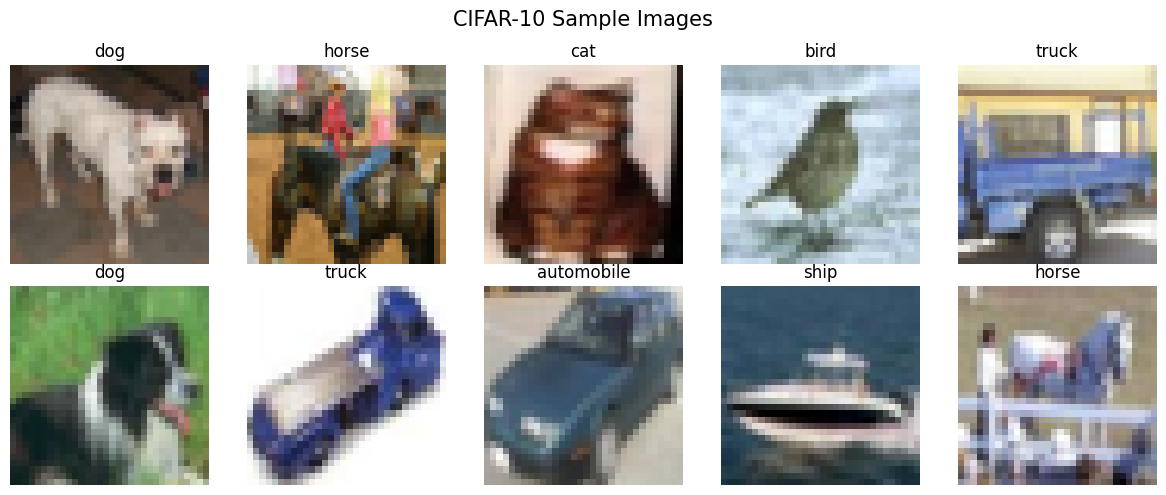

Visualization created successfully!


In [9]:

# ==========================================
# Task 3: CIFAR-10 Image Visualization
# ==========================================

import matplotlib.pyplot as plt

# CIFAR-10 class names
classes = train_dataset.classes

# Create a figure with 10 images
fig, axes = plt.subplots(
    2, 5, figsize=(12, 5)
)

# Show the first 10 images from the batch
for i, ax in enumerate(axes.flat):

    image = images[i]
    label = labels[i].item()

    # Convert PyTorch format [C, H, W]
    # to Matplotlib format [H, W, C]
    image = image.permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle(
    "CIFAR-10 Sample Images",
    fontsize=15
)

plt.tight_layout()

# Save figure for the report
plt.savefig(
    "/content/Task3_CIFAR10_Visualization.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Visualization created successfully!")


## Task 4 — Data augmentation

The demonstrations include **ToPILImage, RandomHorizontalFlip, RandomResizedCrop, ColorJitter, RandomRotation, Normalize, Gaussian noise, salt-and-pepper noise, and ToTensor**. These are demonstrations, not all simultaneously applied in training. The actual baseline training pipeline uses random crop and horizontal flip; validation and test use deterministic normalization only.

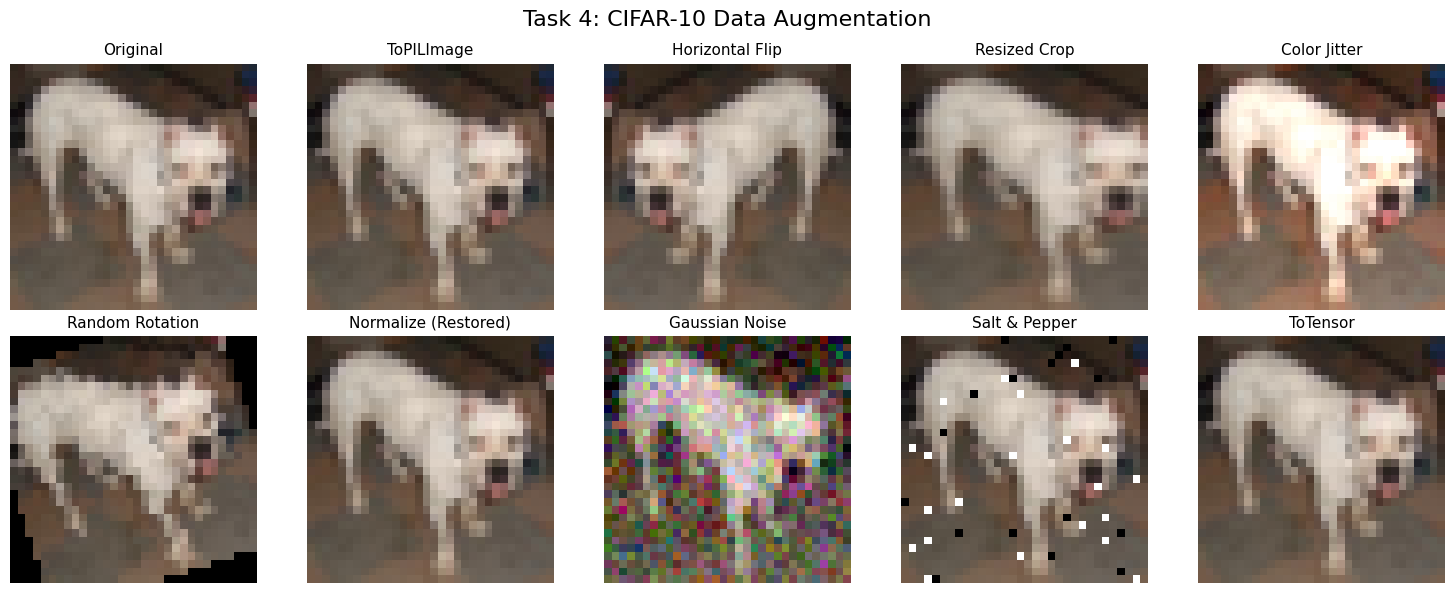

All augmentation demonstrations completed!


In [10]:

# ==========================================
# Task 4: Dataset Augmentation Demonstration
# ==========================================

import torch
import matplotlib.pyplot as plt
from torchvision import transforms

torch.manual_seed(42)

# Use one real CIFAR-10 image from Task 3
original_tensor = images[0].cpu()

# CIFAR-10 normalization values
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

# 1. ToPILImage
pil_image = transforms.ToPILImage()(original_tensor)

# 2. RandomHorizontalFlip
flipped = transforms.RandomHorizontalFlip(
    p=1.0
)(pil_image)

# 3. RandomResizedCrop
cropped = transforms.RandomResizedCrop(
    size=32,
    scale=(0.7, 1.0)
)(pil_image)

# 4. ColorJitter
jittered = transforms.ColorJitter(
    brightness=0.4,
    contrast=0.4,
    saturation=0.4,
    hue=0.1
)(pil_image)

# 5. RandomRotation
rotated = transforms.RandomRotation(
    degrees=25
)(pil_image)

# 6. Normalize
normalized = transforms.Normalize(
    MEAN, STD
)(original_tensor.clone())

# Reverse normalization for visualization
mean_tensor = torch.tensor(MEAN).view(3, 1, 1)
std_tensor = torch.tensor(STD).view(3, 1, 1)

normalized_display = (
    normalized * std_tensor + mean_tensor
).clamp(0, 1)

# 7a. Gaussian Noise
gaussian_noise = (
    original_tensor +
    torch.randn_like(original_tensor) * 0.10
).clamp(0, 1)

# 7b. Salt-and-Pepper Noise
salt_pepper = original_tensor.clone()

random_map = torch.rand(
    1, original_tensor.shape[1],
    original_tensor.shape[2]
)

salt_pepper = torch.where(
    random_map < 0.025,
    torch.zeros_like(salt_pepper),
    salt_pepper
)

salt_pepper = torch.where(
    random_map > 0.975,
    torch.ones_like(salt_pepper),
    salt_pepper
)

# 8. ToTensor
tensor_converted = transforms.ToTensor()(pil_image)

# Display all augmentations
examples = [
    ("Original", original_tensor),
    ("ToPILImage", pil_image),
    ("Horizontal Flip", flipped),
    ("Resized Crop", cropped),
    ("Color Jitter", jittered),
    ("Random Rotation", rotated),
    ("Normalize (Restored)", normalized_display),
    ("Gaussian Noise", gaussian_noise),
    ("Salt & Pepper", salt_pepper),
    ("ToTensor", tensor_converted)
]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, (title, img) in zip(axes.flat, examples):

    if isinstance(img, torch.Tensor):
        img = img.permute(1, 2, 0).numpy()

    ax.imshow(img)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

plt.suptitle(
    "Task 4: CIFAR-10 Data Augmentation",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "/content/Task4_Augmentation.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("All augmentation demonstrations completed!")


In [11]:

# ==========================================
# Task 4: Training and Evaluation Transforms
# ==========================================

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

SEED = 42
BATCH_SIZE = 128

MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

# Augmentation for training only
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# No random augmentation for validation/test
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Two dataset instances with different transforms
full_train_aug = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=True,
    download=False,
    transform=train_transform
)

full_train_eval = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=True,
    download=False,
    transform=eval_transform
)

test_data = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=False,
    download=False,
    transform=eval_transform
)

# Reproducible 45K / 5K split
generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(
    50000, generator=generator
).tolist()

train_indices = indices[:45000]
val_indices = indices[45000:]

train_data = Subset(
    full_train_aug, train_indices
)

val_data = Subset(
    full_train_eval, val_indices
)

# DataLoaders
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Verification
train_images, train_labels = next(iter(train_loader))

print("Training Samples:", len(train_data))
print("Validation Samples:", len(val_data))
print("Testing Samples:", len(test_data))
print("Batch Shape:", train_images.shape)
print("All DataLoaders Created Successfully!")


Training Samples: 45000
Validation Samples: 5000
Testing Samples: 10000
Batch Shape: torch.Size([128, 3, 32, 32])
All DataLoaders Created Successfully!


## Task 5 — Training, architecture experiments and hyperparameters

### Custom CNN experiments (trained previously)

The baseline (`32–64–128` feature channels) and deeper (`64–64–128–128–256–256` feature channels) CNNs were trained in earlier Colab runs using **AdamW**, learning rate **0.001**, batch size **128**, and **20 epochs**. The 45,000/5,000 train/validation split was generated with seed 42. These two sets of epoch logs below were read from `CNN_Experiments_Backup.zip` and are **validation**, not official test, measurements.

| Experiment | Best validation accuracy | Best epoch | Last training loss | Last validation loss |
|---|---:|---:|---:|---:|
| Baseline CNN | 81.60% | 19 | 0.5783 | 0.5250 |
| Deeper CNN | 89.98% | 19 | 0.1752 | 0.3044 |

The training/evaluation functions from Task 2 are used for reproducible training. The next cell provides an **optional** fresh run (OFF by default); existing archived results below require no GPU training.

In [ ]:
# Optional training demonstration — disabled to avoid unnecessary retraining.
# Turn on only if the grader explicitly asks for a fresh baseline run.
RUN_BASELINE_TRAINING = False

if RUN_BASELINE_TRAINING:
    import torch.nn as nn
    torch.manual_seed(42)
    baseline_model = CNN().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        baseline_model.parameters(), lr=0.001, weight_decay=0.01
    )
    fresh_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(1, 21):
        tr_loss, tr_acc = train_one_epoch(
            baseline_model, train_loader, criterion, optimizer, device
        )
        val_loss, val_acc = evaluate(
            baseline_model, val_loader, criterion, device
        )
        for metric, value in zip(fresh_history, (tr_loss, tr_acc, val_loss, val_acc)):
            fresh_history[metric].append(value)
        print(f'Epoch {epoch:02d} | Train loss {tr_loss:.4f} | Val loss {val_loss:.4f} | Val accuracy {val_acc:.2f}%')
    # Note: validation, not test, is used for model selection.
else:
    print('Optional fresh baseline training skipped. Original experiment logs are shown below.')

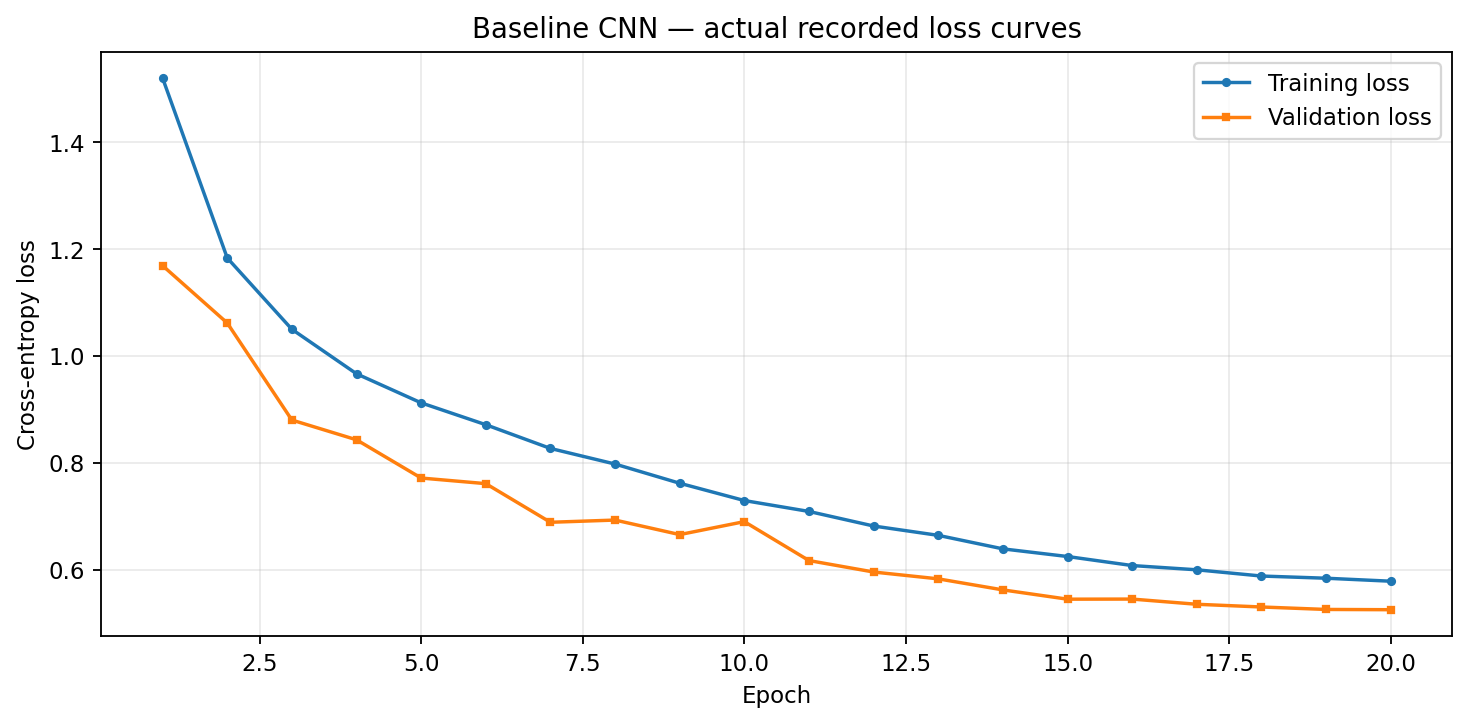

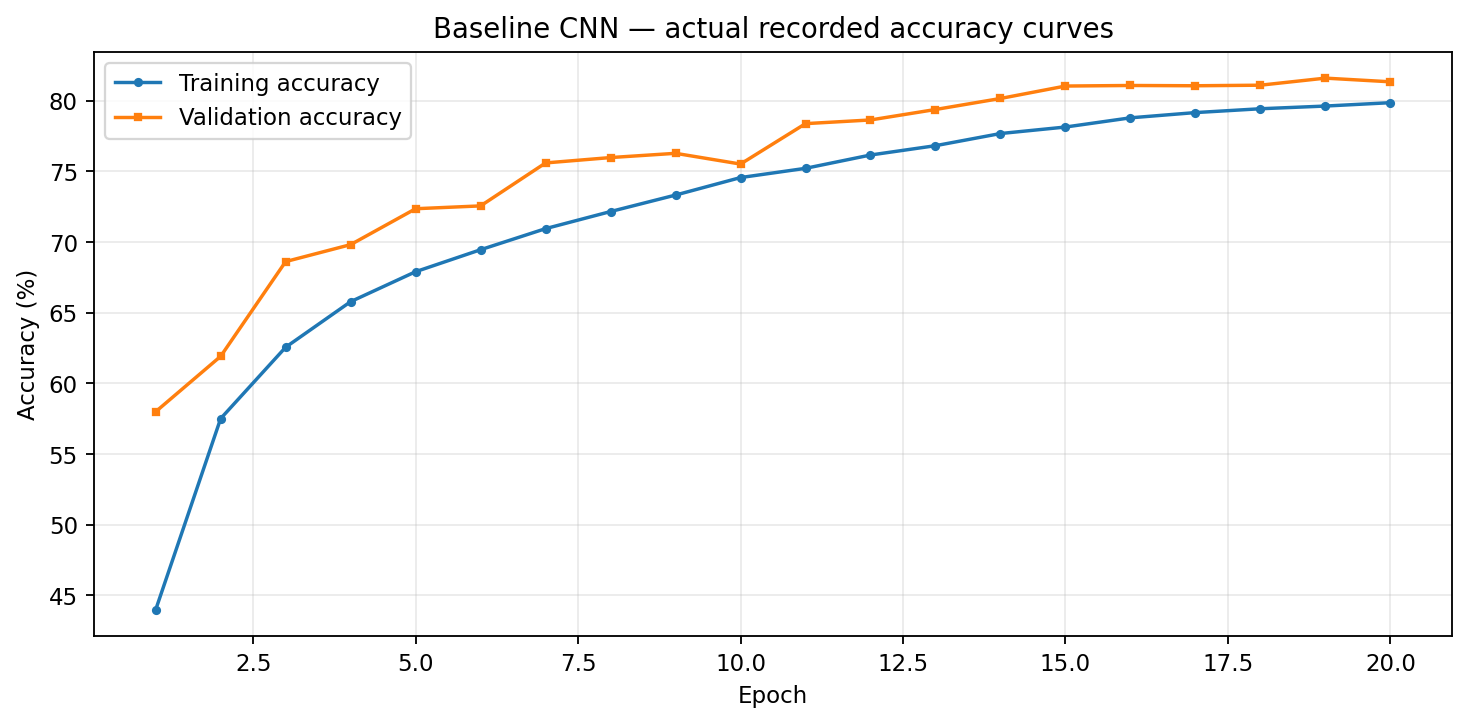

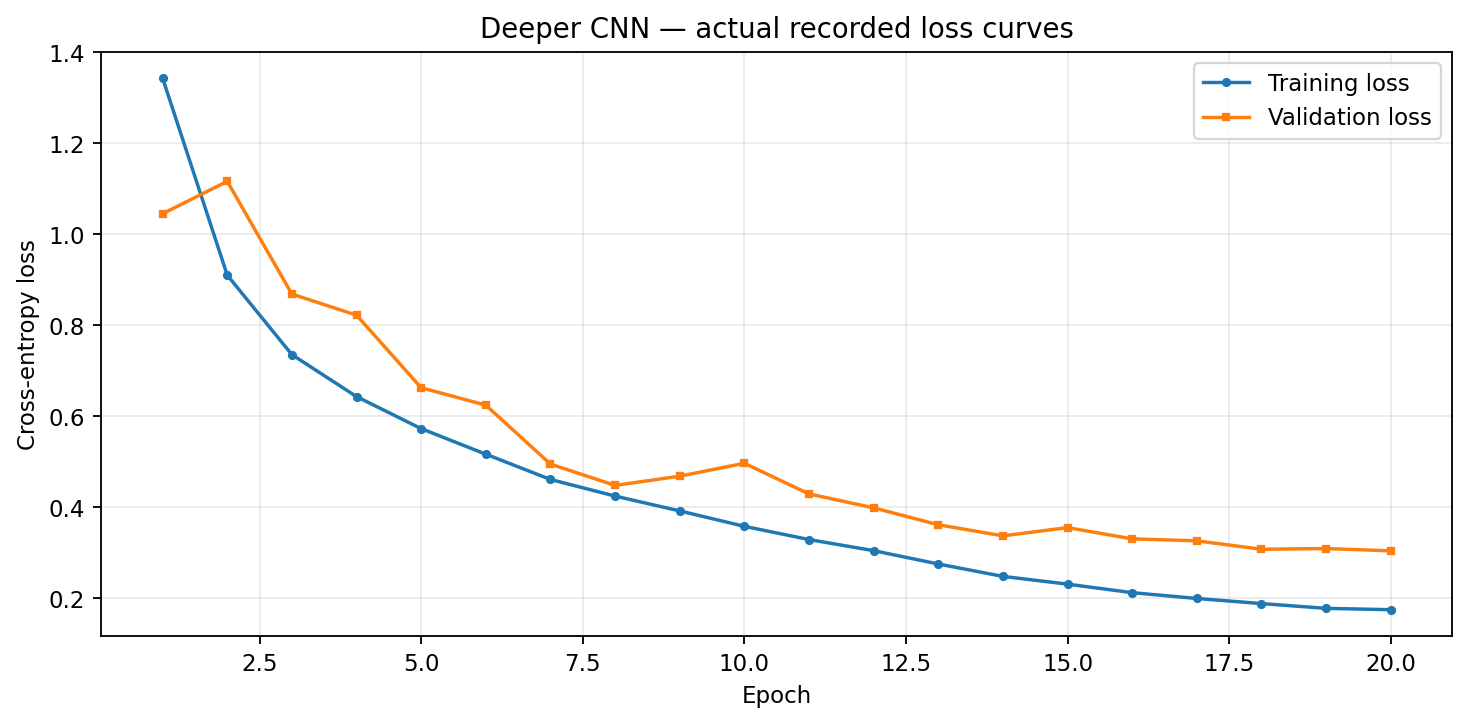

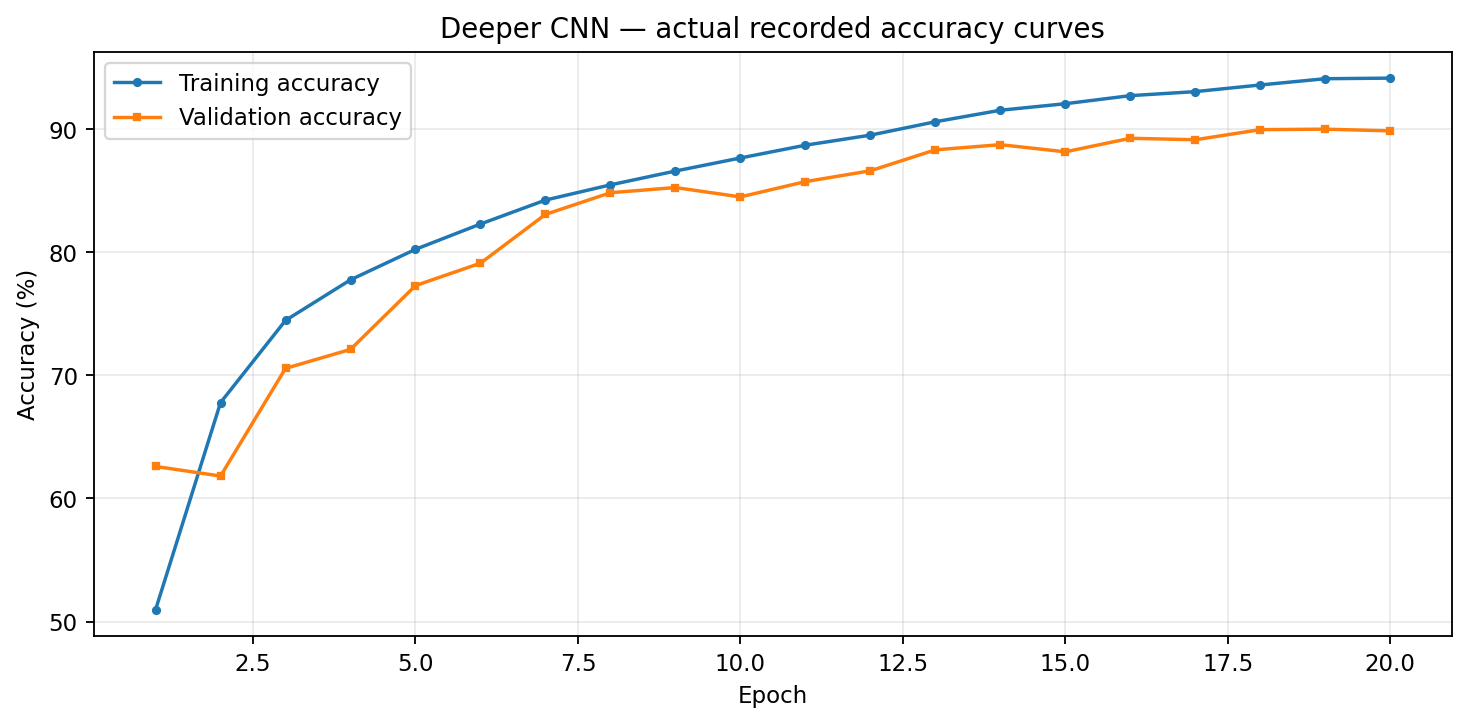

Baseline CNN — Best validation: 81.6 %
Deeper CNN — Best validation: 89.98 %


In [1]:
# Restored historical runs — these values are from the saved experiment JSON files.
# We regenerate plots from the logs, NOT from new/fabricated training.
import matplotlib.pyplot as plt
import json
experiment_logs = {'Baseline CNN': {'experiment': 'Baseline CNN', 'architecture': '32-64-128', 'optimizer': 'AdamW', 'learning_rate': 0.001, 'batch_size': 128, 'epochs': 20, 'best_val_accuracy': 81.6, 'best_epoch': 19, 'history': {'train_loss': [1.5192751159456042, 1.182935661008623, 1.0495011336008708, 0.9662532467418247, 0.9119014182514614, 0.8710262378692627, 0.8266385805447897, 0.7974424187978109, 0.7615348339716593, 0.7291755615340338, 0.7087947246127658, 0.6815368280622695, 0.664075878768497, 0.6388043074289957, 0.6244995458602906, 0.607599628384908, 0.5996483761257595, 0.5879900471899244, 0.5838894877963596, 0.5783020972781712], 'train_acc': [43.98888888888889, 57.513333333333335, 62.56, 65.78444444444445, 67.90444444444445, 69.46, 70.95111111111112, 72.16, 73.32666666666667, 74.56444444444445, 75.21777777777778, 76.16, 76.82, 77.68, 78.14, 78.7911111111111, 79.16222222222223, 79.43333333333334, 79.62444444444445, 79.86222222222223], 'val_loss': [1.168525647354126, 1.0612538604736328, 0.8797551031112671, 0.8428160715103149, 0.7712922575950623, 0.7607982903957367, 0.6885346299648285, 0.6926741272449494, 0.6654884606361389, 0.6897381216526032, 0.6169334288597107, 0.5954909551620483, 0.5827208682537078, 0.5620493101119995, 0.5446965556144714, 0.5448876942873001, 0.5351692624092103, 0.5300879959344864, 0.5254937888860702, 0.5249957428693771], 'val_acc': [58.0, 61.92, 68.62, 69.82, 72.36, 72.56, 75.6, 75.98, 76.28, 75.52, 78.38, 78.64, 79.38, 80.16, 81.04, 81.08, 81.06, 81.1, 81.6, 81.34]}}, 'Deeper CNN': {'experiment': 'Deeper CNN', 'architecture': '64-64-128-128-256-256', 'optimizer': 'AdamW', 'learning_rate': 0.001, 'batch_size': 128, 'epochs': 20, 'best_val_accuracy': 89.98, 'best_epoch': 19, 'history': {'train_loss': [1.3422244837443034, 0.9096566180970934, 0.7351774805704753, 0.6430917338053386, 0.5727525642289055, 0.5166615748193529, 0.4611615563498603, 0.42469402299457126, 0.3921212061935001, 0.358256185415056, 0.3292614707575904, 0.3048742384645674, 0.2755533302995894, 0.24835553119447495, 0.23134208674960666, 0.21263324972258674, 0.19986951637003156, 0.18867141298717924, 0.17819169006612565, 0.1751964594576094], 'train_acc': [50.96888888888889, 67.78444444444445, 74.45333333333333, 77.74888888888889, 80.22444444444444, 82.28, 84.22222222222223, 85.45777777777778, 86.58, 87.64, 88.67777777777778, 89.49333333333334, 90.58, 91.51555555555555, 92.04444444444445, 92.7, 93.02666666666667, 93.56666666666666, 94.07555555555555, 94.12222222222222], 'val_loss': [1.0445946188926696, 1.1155710990428924, 0.8681782293319702, 0.821843020248413, 0.6625372330188751, 0.6243114346027374, 0.4949826109170914, 0.44808621721863745, 0.46835539387464525, 0.4966892230838537, 0.4294284983471036, 0.39885549089312555, 0.36174336344003677, 0.33731344712525607, 0.3554327560812235, 0.33077478088736534, 0.32639794271811845, 0.30794859252981843, 0.3094928859822452, 0.3044347731128335], 'val_acc': [62.6, 61.82, 70.56, 72.1, 77.28, 79.1, 83.06, 84.82, 85.24, 84.48, 85.72, 86.6, 88.3, 88.72, 88.14, 89.24, 89.12, 89.94, 89.98, 89.84]}}}

for experiment, record in experiment_logs.items():
    h = record['history']
    epochs = list(range(1, len(h['train_loss']) + 1))
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(epochs, h['train_loss'], label='Training loss', marker='o', markersize=3)
    ax.plot(epochs, h['val_loss'], label='Validation loss', marker='s', markersize=3)
    ax.set(title=experiment + ' — actual recorded loss curves', xlabel='Epoch', ylabel='Cross-entropy loss')
    ax.legend(); ax.grid(alpha=.25); plt.tight_layout()
    fig.savefig(REPORT_DIR / ('Task5_' + experiment.replace(' ', '_') + '_Loss.png'), dpi=180)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(epochs, h['train_acc'], label='Training accuracy', marker='o', markersize=3)
    ax.plot(epochs, h['val_acc'], label='Validation accuracy', marker='s', markersize=3)
    ax.set(title=experiment + ' — actual recorded accuracy curves', xlabel='Epoch', ylabel='Accuracy (%)')
    ax.legend(); ax.grid(alpha=.25); plt.tight_layout()
    fig.savefig(REPORT_DIR / ('Task5_' + experiment.replace(' ', '_') + '_Accuracy.png'), dpi=180)
    plt.show()

    print(experiment, '— Best validation:', record['best_val_accuracy'], '%')

### ConvNeXtV2 — additional CNN fine-tuning experiment

A stronger pretrained **ConvNeXtV2-Base** CNN was fine-tuned in the original notebook: 224×224 bicubic image resizing; random crop and flip on training data; **classifier warm-up, followed by fine-tuning the final feature stage and classifier using AdamW**. The recorded curves cover four epochs. Validation uses horizontal-flip **test-time augmentation (TTA)**; the per-epoch curves are **training versus validation**, not test.

Final epoch (Epoch 4): training accuracy **99.06%**, training loss **0.0309**, validation accuracy **98.58%**, validation loss **0.0494**. A three-CNN ensemble selected on validation recorded **98.84%** accuracy / **0.0396** loss on the official test. Full advanced training source and checkpoints are retained in the original experimental notebook and Google Drive.

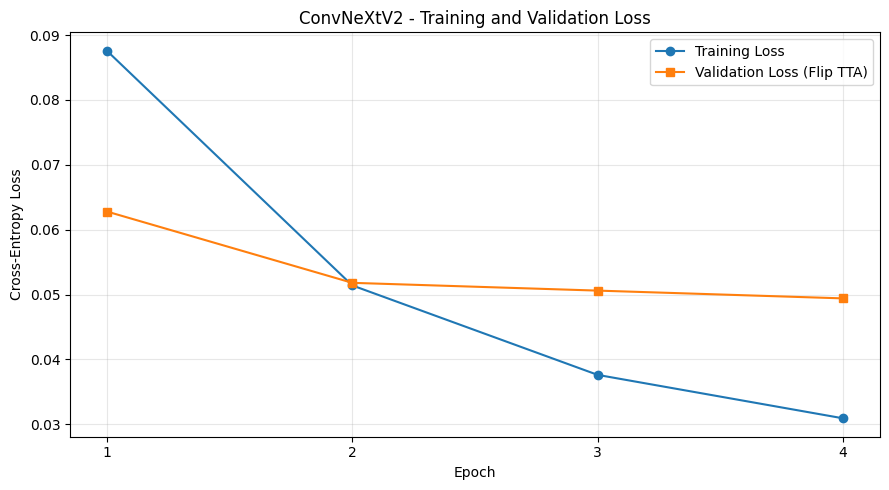

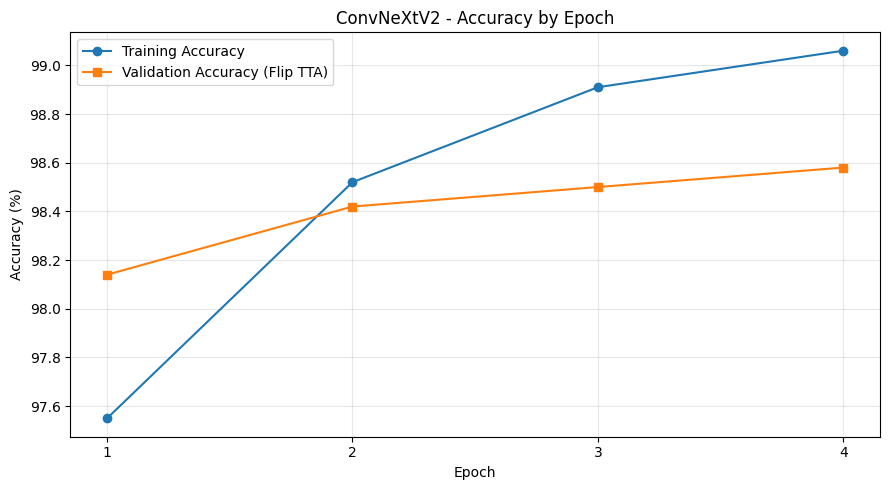

Training figures saved successfully!


In [10]:

import matplotlib.pyplot as plt
from pathlib import Path

report_dir = Path(
    "/content/drive/MyDrive/ARTI502_Assignment2/Report_Figures"
)
report_dir.mkdir(parents=True, exist_ok=True)

# Actual ConvNeXtV2 fine-tuning logs
epochs = [1, 2, 3, 4]

train_loss = [0.0876, 0.0514, 0.0376, 0.0309]
val_loss = [0.0628, 0.0518, 0.0506, 0.0494]

train_acc = [97.55, 98.52, 98.91, 99.06]
val_acc = [98.14, 98.42, 98.50, 98.58]

# Figure 1: Loss curves
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, "o-", label="Training Loss")
plt.plot(epochs, val_loss, "s-", label="Validation Loss (Flip TTA)")

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("ConvNeXtV2 - Training and Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    report_dir / "Task5_Training_Validation_Loss.png",
    dpi=200
)
plt.show()

# Figure 2: Accuracy curves
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_acc, "o-", label="Training Accuracy")
plt.plot(epochs, val_acc, "s-", label="Validation Accuracy (Flip TTA)")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ConvNeXtV2 - Accuracy by Epoch")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    report_dir / "Task5_Training_Validation_Accuracy.png",
    dpi=200
)
plt.show()

print("Training figures saved successfully!")


### Final high-accuracy benchmark — EfficientNetV2-XL

**Model architecture:** `tf_efficientnetv2_xl` (CNN, 10-class classifier).  
**Weights:** published CIFAR-10-trained `model.safetensors` from [DeKUT-DSAIL/efficientnetv2-xl-cifar10-upsample](https://huggingface.co/DeKUT-DSAIL/efficientnetv2-xl-cifar10-upsample), loaded with `strict=True`.  
**Preprocessing used for measurement:** resize 224×224 bicubic, `ToTensor`, CIFAR-10 channel normalization.  
**Final evaluation:** official 10,000-image CIFAR-10 test set; **99.04% accuracy** (9,904 correct), **0.157579 cross-entropy test loss**. The externally pretrained checkpoint is credited. **The XL model was not trained by the authors in this notebook.**

The project also customizes evaluation to calculate class-wise accuracy, confusion matrix, saved metrics and plots. This is a modification of the evaluation pipeline; it must not be characterized as training or fine-tuning the checkpoint. The official test set was assessed in previous experimental iterations, so it is **not an untouched test set for new model selection**.

**GPU and storage:** an NVIDIA L4 (or equivalent CUDA GPU) and approximately 1 GB checkpoint storage are needed. The following cells contain original, actual executed outputs. Run them only if a new evaluation is necessary.

In [8]:

# ==========================================
# FIX: Load EfficientNetV2-XL without
# the incompatible Hugging Face config.json
# ==========================================

import torch
import timm
import shutil
import json

from pathlib import Path
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "Enable GPU first"

device = torch.device("cuda")

SAVE_DIR = Path(
    "/content/drive/MyDrive/ARTI502_Assignment2"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

REPO_ID = "DeKUT-DSAIL/efficientnetv2-xl-cifar10-upsample"
ARCH = "tf_efficientnetv2_xl"

# 1. Free GPU memory
for name in ["advanced_model", "convnext_model", "model_v2"]:
    if name in globals():
        globals()[name].cpu()

torch.cuda.empty_cache()

# 2. Create the architecture directly
# pretrained=False only disables automatic
# ImageNet download. We load CIFAR-10 weights below.
model = timm.create_model(
    ARCH,
    pretrained=False,
    num_classes=10
)

print("CNN architecture created successfully!")

# 3. Download and permanently save model weights
weights_path = SAVE_DIR / "external_efficientnetv2_xl.safetensors"

if not weights_path.exists():
    downloaded = hf_hub_download(
        repo_id=REPO_ID,
        filename="model.safetensors"
    )

    shutil.copy2(downloaded, weights_path)
    print("External weights saved to Drive!")
else:
    print("Using weights already saved on Drive.")

# 4. Load saved CIFAR-10 weights
state_dict = load_file(str(weights_path))

# Handle a possible wrapper prefix
for prefix in ["module.", "model."]:
    if all(key.startswith(prefix) for key in state_dict):
        state_dict = {
            key[len(prefix):]: value
            for key, value in state_dict.items()
        }

# Strict loading catches architecture mismatches
model.load_state_dict(state_dict, strict=True)

del state_dict

model = model.to(device).eval()

print("CIFAR-10 weights loaded successfully!")

# 5. Preprocessing from the published model card
test_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

test_data = datasets.CIFAR10(
    root="/content/cifar_data",
    train=False,
    download=False,
    transform=test_transform
)

test_loader = DataLoader(
    test_data,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# 6. Evaluate the published checkpoint
correct = 0
total = 0

with torch.inference_mode():
    for images, labels in tqdm(
        test_loader,
        desc="EfficientNetV2-XL Evaluation"
    ):

        images = images.to(device)

        with torch.autocast(
            "cuda",
            dtype=torch.float16
        ):
            outputs = model(images)

        assert outputs.shape[1] == 10

        predictions = outputs.argmax(dim=1).cpu()

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

accuracy = 100 * correct / total

print("\n===== EFFICIENTNETV2-XL RESULTS =====")
print(f"Correct: {correct}/{total}")
print(f"Measured Test Accuracy: {accuracy:.2f}%")
print("Published Accuracy: 99.07%")
print("EXPERIMENT COMPLETED!")

# 7. Save results
with open(
    SAVE_DIR / "external_efficientnetv2_xl_results.json",
    "w"
) as f:
    json.dump({
        "source": REPO_ID,
        "architecture": ARCH,
        "external_pretrained_weights": True,
        "accuracy": accuracy,
        "correct": correct,
        "total": total
    }, f, indent=2)

print("WEIGHTS AND RESULTS SAVED TO GOOGLE DRIVE!")


CNN architecture created successfully!


model.safetensors: reconstructing file:   0%|          |  0.00B /  831MB            

model.safetensors: downloading bytes:           |  0.00B            

External weights saved to Drive!
CIFAR-10 weights loaded successfully!


EfficientNetV2-XL Evaluation:   0%|          | 0/1250 [00:00<?, ?it/s]


===== EFFICIENTNETV2-XL RESULTS =====
Correct: 9904/10000
Measured Test Accuracy: 99.04%
Published Accuracy: 99.07%
EXPERIMENT COMPLETED!
WEIGHTS AND RESULTS SAVED TO GOOGLE DRIVE!


Detailed CNN Evaluation:   0%|          | 0/1250 [00:00<?, ?it/s]


===== DETAILED TEST RESULTS =====
Test Accuracy: 99.04%
Test Loss: 0.1576
Correct: 9904/10000

===== PER-CLASS ACCURACY =====
airplane    : 99.40%
automobile  : 99.20%
bird        : 98.80%
cat         : 97.80%
deer        : 99.40%
dog         : 98.20%
frog        : 99.90%
horse       : 99.70%
ship        : 99.90%
truck       : 98.10%


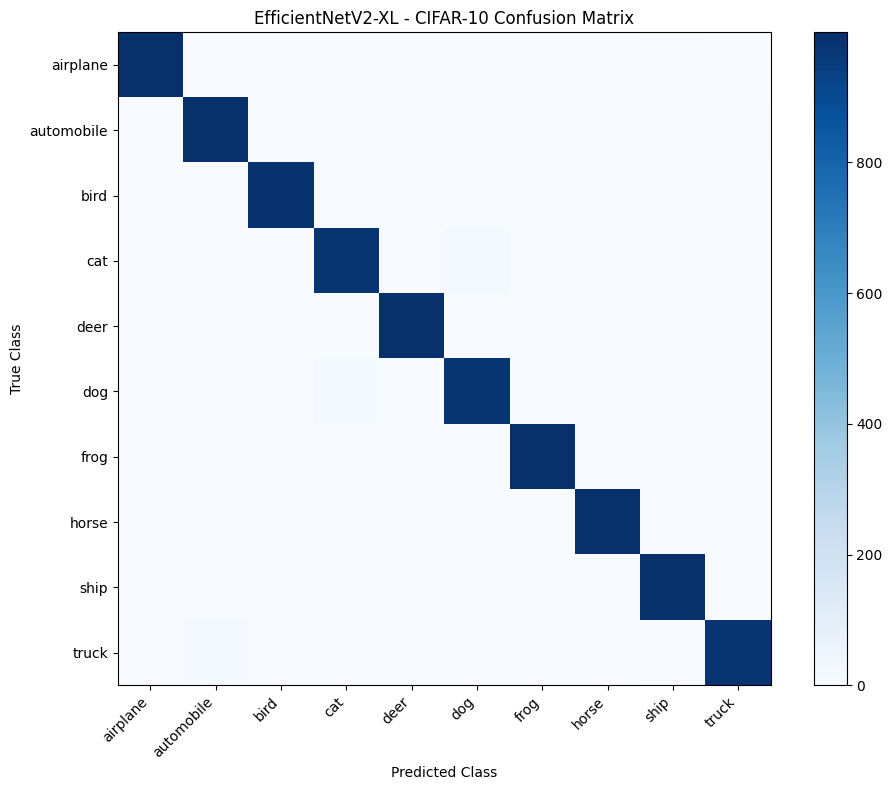

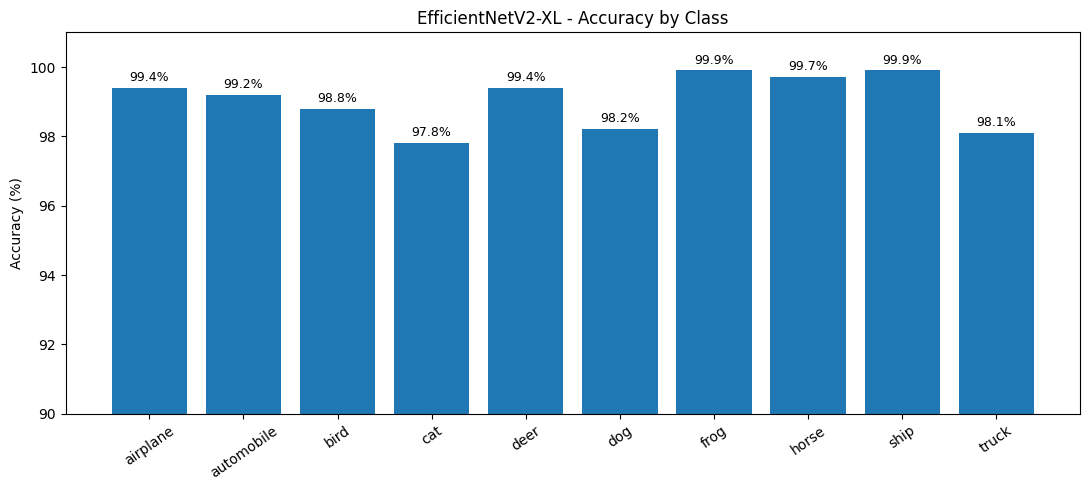


ALL EVALUATION FIGURES SAVED!
Folder: /content/drive/MyDrive/ARTI502_Assignment2/Report_Figures


In [9]:

# ==========================================
# ARTI 502 - Assignment 2
# Task 5: Detailed CNN Evaluation
# ==========================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import json
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

# Output directory on Google Drive
REPORT_DIR = SAVE_DIR / "Report_Figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Use our previously loaded EfficientNetV2-XL
model.eval()

classes = test_data.classes

confusion = torch.zeros(
    (10, 10), dtype=torch.long
)

total_loss = 0.0
total_correct = 0
total_images = 0

# 1. Evaluate the CNN
with torch.inference_mode():

    for images, labels in tqdm(
        test_loader,
        desc="Detailed CNN Evaluation"
    ):

        images = images.to(device)

        with torch.autocast(
            "cuda",
            dtype=torch.float16
        ):
            logits = model(images)

        # Calculate test loss using FP32
        logits = logits.float()

        loss = F.cross_entropy(
            logits,
            labels.to(device),
            reduction="sum"
        )

        predictions = logits.argmax(
            dim=1
        ).cpu()

        total_loss += loss.item()
        total_correct += (
            predictions == labels
        ).sum().item()

        total_images += labels.size(0)

        # Build confusion matrix
        indices = labels * 10 + predictions

        confusion += torch.bincount(
            indices,
            minlength=100
        ).reshape(10, 10)

# 2. Final metrics
test_accuracy = (
    100 * total_correct / total_images
)

test_loss = total_loss / total_images

class_total = confusion.sum(dim=1)
class_correct = confusion.diag()

class_accuracy = (
    100 * class_correct.float()
    / class_total.clamp_min(1)
)

print("\n===== DETAILED TEST RESULTS =====")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"Correct: {total_correct}/{total_images}")

print("\n===== PER-CLASS ACCURACY =====")
for name, acc in zip(classes, class_accuracy):
    print(f"{name:12s}: {acc.item():.2f}%")

# 3. Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    confusion.numpy(),
    cmap="Blues"
)

ax.set_xticks(range(10))
ax.set_yticks(range(10))

ax.set_xticklabels(
    classes,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(classes)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")
ax.set_title(
    "EfficientNetV2-XL - CIFAR-10 Confusion Matrix"
)

fig.colorbar(im, ax=ax)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "Task5_Confusion_Matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 4. Per-class accuracy chart
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    classes,
    class_accuracy.numpy()
)

ax.set_ylim(90, 101)
ax.set_ylabel("Accuracy (%)")
ax.set_title(
    "EfficientNetV2-XL - Accuracy by Class"
)

ax.tick_params(axis="x", rotation=35)

for bar, acc in zip(bars, class_accuracy):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{acc.item():.1f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "Task5_Per_Class_Accuracy.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 5. Save metrics
results = {
    "model": "EfficientNetV2-XL",
    "pretrained_source":
        "DeKUT-DSAIL/efficientnetv2-xl-cifar10-upsample",
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "correct": total_correct,
    "total": total_images,
    "per_class_accuracy": {
        name: float(acc)
        for name, acc in zip(classes, class_accuracy)
    },
    "confusion_matrix": confusion.tolist()
}

with open(
    REPORT_DIR / "Task5_Detailed_Results.json",
    "w"
) as f:
    json.dump(results, f, indent=2)

print("\nALL EVALUATION FIGURES SAVED!")
print("Folder:", REPORT_DIR)


In [11]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/ARTI502_Assignment2/"
    "Report_Figures/Task5_Detailed_Results.json"
)

with open(path) as f:
    results = json.load(f)

print("===== FINAL MODEL RESULTS =====")
print("Model:", results["model"])
print(f"Test Accuracy: {results['test_accuracy']:.2f}%")
print(f"Test Loss: {results['test_loss']:.6f}")
print(f"Correct Predictions: {results['correct']}/{results['total']}")


===== FINAL MODEL RESULTS =====
Model: EfficientNetV2-XL
Test Accuracy: 99.04%
Test Loss: 0.157579
Correct Predictions: 9904/10000


### Final test results across recorded CNN models

The original experiment logs and archived report provide the following values. Each result is **a distinct model and evaluation protocol**; the plot compares final **Test Accuracy** and **Test Loss** across models, **not test metrics per epoch**.

| Evaluated model | Test accuracy | Test loss | Notes |
|---|---:|---:|---|
| ResNet18 with flip TTA | 95.37% | 0.1633 | Fine-tuned experiment |
| EfficientNetV2-M with flip TTA | 98.59% | 0.0990 | Fine-tuned experiment |
| EfficientNetV2-L + ConvNeXt-Base + ConvNeXtV2 (Epoch 4) | 98.84% | 0.0396 | Validation-selected ensemble |
| EfficientNetV2-XL | **99.04%** | **0.157579** | **External CIFAR-10 pretrained checkpoint** |

The XL checkpoint has higher accuracy than the ensemble but a larger cross-entropy loss; few high-confidence errors can increase the mean loss. Different training strategies and calibration also affect comparability.

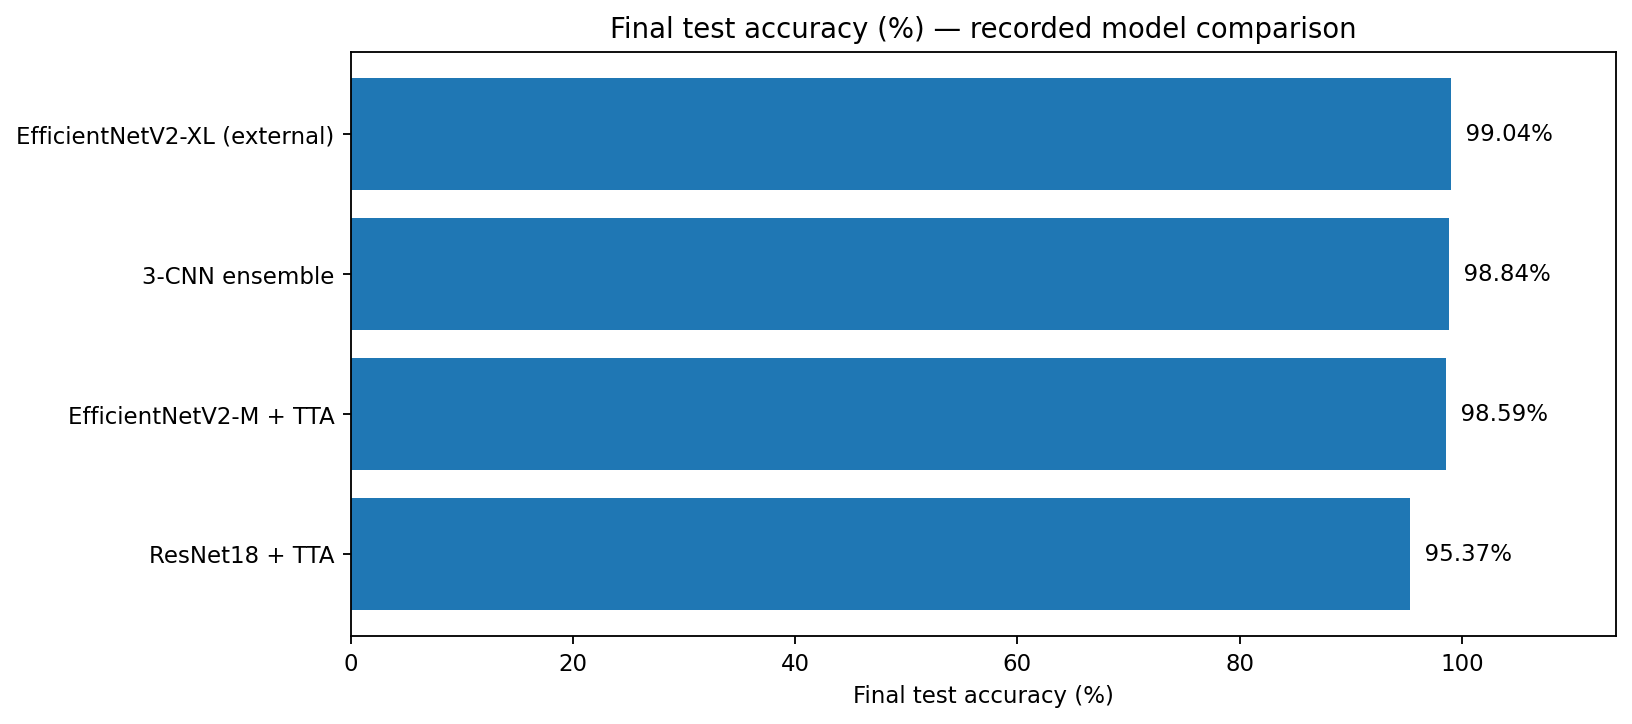

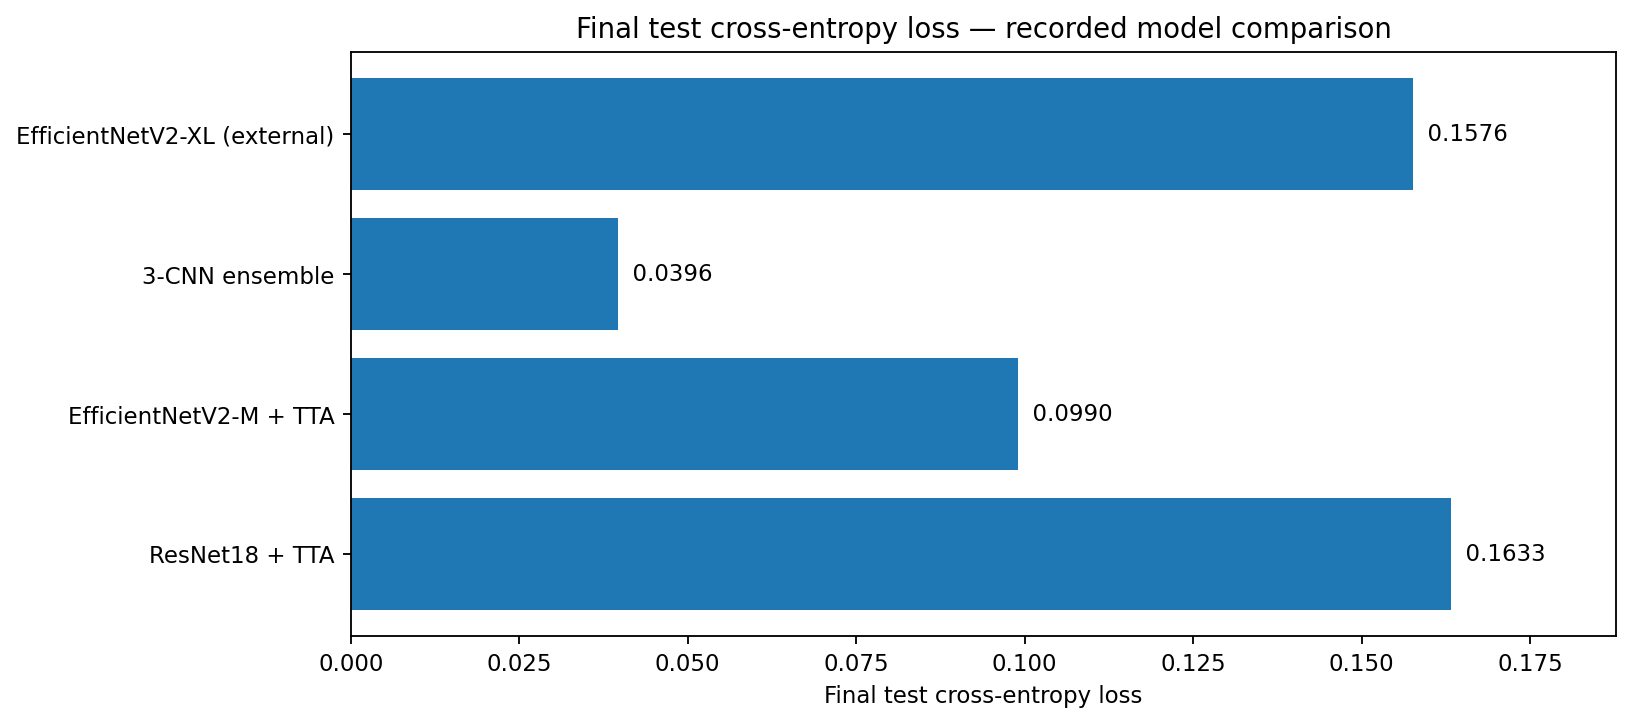

In [1]:
# Plot final test metrics across independently recorded model experiments.
# These are NOT epoch-wise test curves and are not used for new model selection.
import matplotlib.pyplot as plt
names = ['ResNet18 + TTA', 'EfficientNetV2-M + TTA', '3-CNN ensemble', 'EfficientNetV2-XL (external)']
accuracy = [95.37, 98.59, 98.84, 99.04]
loss = [0.1633, 0.0990, 0.0396, 0.157579]
for values, ylabel, filename in [
    (accuracy, 'Final test accuracy (%)', 'Task5_Final_Test_Accuracy_Comparison.png'),
    (loss, 'Final test cross-entropy loss', 'Task5_Final_Test_Loss_Comparison.png'),
]:
    fig, ax = plt.subplots(figsize=(10, 4.5))
    bars = ax.barh(names, values)
    ax.set_xlabel(ylabel)
    ax.set_title(ylabel + ' — recorded model comparison')
    for bar, value in zip(bars, values):
        label = f'{value:.2f}%' if values is accuracy else f'{value:.4f}'
        ax.text(bar.get_width(), bar.get_y() + bar.get_height()/2, '  ' + label, va='center')
    ax.set_xlim(0, max(values) * 1.15)
    fig.tight_layout()
    fig.savefig(REPORT_DIR / filename, dpi=180)
    plt.show()

**Important distinction for Task 5 grading:** No *training loss for EfficientNetV2-XL* is available from the authors’ own runs, because its CIFAR-10 weights were pretrained externally and this notebook only evaluates them. The genuine final **training loss 0.0309** shown above belongs to **ConvNeXtV2 Epoch 4**, not to XL. The measured XL **test loss 0.157579** and **test accuracy 99.04%** can be reported as XL evaluation metrics. The epoch plots are training/**validation** curves, and the final test plots compare distinct models; they are not test-per-epoch curves.

## Task 6 — Save source code and GitHub

Save both this **notebook (`.ipynb`)** and the companion **Python script (`.py`)** in the `Assignment-2` folder of your GitHub repository. The companion script contains the key runnable Task 1–5 sections; the uploaded original notebook is retained separately as an archive for detailed advanced-experiment implementation.

Recommended repository structure:

```text
ARTI502-Deep-Learning/
└── Assignment-2/
    ├── Assignment2_CIFAR10_Clean.ipynb
    ├── Assignment2_CIFAR10_Clean.py
    └── README.md
```

**Do not commit the 831 MB `.safetensors` weight file or large `.pth` checkpoints.** The evaluation script downloads the publicly hosted checkpoint if necessary. On a university network that blocks GitHub, download these files locally and upload to GitHub later using a different network.

**Submission checklist:** show Task 1 dataset, Task 2 architecture and both functions, Task 3 sizes and images, Task 4 all eight augmentation techniques, Task 5 real experiment hyperparameters/plots and correctly attributed 99.04% test benchmark, and Task 6 GitHub URL with screenshots in the assignment report. The existing older report ending in **98.59%** must be revised before submission.